# Task 9 — HR FAQ Chatbot and Intent Classification

**Project:** CortexHR / employee-ml-project  
**Goal:** Train an intent classifier using TF-IDF + Logistic Regression, evaluate on the supplied unseen test set, answer HR policy questions from `hr_faq.csv`, and provide a safe fallback for uncertain messages.

## Task requirements
- Inspect 20 training messages, including noisy examples.
- Clean text without destroying useful meaning.
- Train TF-IDF + Logistic Regression.
- Evaluate on the untouched `chatbot_test_set.csv` using accuracy and a confusion matrix.
- Inspect misclassified examples.
- Use a confidence threshold of **0.55**.
- Answer policy FAQs from `hr_faq.csv`; refuse `salary_of_other`.
- Save a model bundle and generate a FastAPI integration module for `/v1/chat`.

**Important:** The test set is used only for final evaluation. Do not train or tune the model using its labels. This notebook does not overwrite your existing API `main.py` or earlier task files.


In [1]:
# 1. Imports and project paths

from pathlib import Path
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.metrics.pairwise import cosine_similarity
import joblib

warnings.filterwarnings("ignore", category=UserWarning)

def find_project_root(start: Path = None) -> Path:
    """Find the repository root by locating the expected data folder/files."""
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "data" / "chatbot_nlu_training.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/chatbot_nlu_training.csv. "
        "Run this notebook from the repository or place it under notebooks/."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "chatbot_nlu_training.csv"
TEST_PATH = DATA_DIR / "chatbot_test_set.csv"
FAQ_PATH = DATA_DIR / "hr_faq.csv"

print("Project root:", PROJECT_ROOT)
print("Training file exists:", TRAIN_PATH.exists())
print("Test file exists:", TEST_PATH.exists())
print("FAQ file exists:", FAQ_PATH.exists())


Project root: /workspace
Training file exists: True
Test file exists: True
FAQ file exists: True


In [2]:
# 2. Load the three datasets and validate their required columns

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
faq_df = pd.read_csv(FAQ_PATH)

required_train = {"text", "intent"}
required_test = {"text", "expected_intent"}
required_faq = {"question", "answer", "category"}

assert required_train.issubset(train_df.columns), f"Training columns missing: {required_train - set(train_df.columns)}"
assert required_test.issubset(test_df.columns), f"Test columns missing: {required_test - set(test_df.columns)}"
assert required_faq.issubset(faq_df.columns), f"FAQ columns missing: {required_faq - set(faq_df.columns)}"

print(f"Training shape: {train_df.shape}")
print(f"Test shape:     {test_df.shape}")
print(f"FAQ shape:      {faq_df.shape}")

display(pd.DataFrame({
    "dataset": ["training", "test", "FAQ"],
    "rows": [len(train_df), len(test_df), len(faq_df)],
    "columns": [", ".join(train_df.columns), ", ".join(test_df.columns), ", ".join(faq_df.columns)],
}))


Training shape: (858, 4)
Test shape:     (132, 4)
FAQ shape:      (30, 5)


,dataset,rows,columns
0,training,858,"example_id, text, intent, entities"
1,test,132,"test_id, text, expected_intent, expected_entities"
2,FAQ,30,"faq_id, question, answer, category, policy_source"


In [3]:
# 3. Inspect missing values, intent balance, duplicates, and 20 example messages

print("Missing values — training:")
display(train_df.isna().sum().to_frame("missing_count"))

print("Missing values — test:")
display(test_df.isna().sum().to_frame("missing_count"))

print("Missing values — FAQ:")
display(faq_df.isna().sum().to_frame("missing_count"))

print(f"\nUnique training intents: {train_df['intent'].nunique()}")
print("Training examples per intent:")
display(train_df["intent"].value_counts().sort_index().to_frame("count"))

# Inspect the raw text as provided, including typos and noisy phrasing.
pd.set_option("display.max_colwidth", 120)
print("20 training messages (fixed random_state=42):")
display(
    train_df[["text", "intent"]]
    .sample(n=min(20, len(train_df)), random_state=42)
    .reset_index(drop=True)
)

# Duplicate audit after basic text normalization; we report rather than delete blindly.
def normalize_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["text_normalized"] = train_df["text"].map(normalize_text)
duplicate_mask = train_df.duplicated(subset=["text_normalized"], keep=False)
print("Rows involved in duplicate normalized message groups:", int(duplicate_mask.sum()))
if duplicate_mask.any():
    display(
        train_df.loc[
            duplicate_mask,
            ["text", "intent", "text_normalized"]
        ]
        .sort_values("text_normalized")
        .head(30)
        [["text", "intent"]]
    )


Missing values — training:


,missing_count
example_id,0
text,0
intent,0
entities,694


Missing values — test:


,missing_count
test_id,0
text,0
expected_intent,0
expected_entities,106


Missing values — FAQ:


...

,count
intent,
apply_leave_howto,26
attendance_summary,26
attrition_risk_query,26
chitchat,26
goodbye,26
greet,26
headcount_forecast,26
help,26
holiday_list,26


20 training messages (fixed random_state=42):


,text,intent
0,quick question: what is the expense claim process urgently,reimbursement_policy
1,plesae talk to you later ?,goodbye
2,I want to know can the notice period be bought out urgently,notice_period_policy
3,leave balance please please,leave_balance
4,headcount forecast for Operations,headcount_forecast
5,"hey, what should we pay a Data Analyst ?",salary_band_query
6,qucik question: how do I check my pf balance,pf_info
7,can you tell me check my leave balance urgently,leave_balance
8,"I want to know great, thanks urgently",thanks
9,I want to know who is in my team urgently,team_members


Rows involved in duplicate normalized message groups: 14


,text,intent
110,can i work remotely,wfh_policy
772,can I work remotely,wfh_policy
201,can you tell me rank resumes for hr executive,resume_score_request
509,can you tell me rank resumes for HR Executive,resume_score_request
298,can you tell me who do i report to,my_manager
699,can you tell me who do I report to,my_manager
112,I want to know what is the leave application process urgently,apply_leave_howto
786,i want to know what is the leave application process urgently,apply_leave_howto
20,i want to know when will i be confirmed ?,probation_policy
65,I want to know when will I be confirmed ?,probation_policy


## Text cleaning decision

We only lowercase text and normalize whitespace. We deliberately **do not remove all punctuation, remove stop words, or stem words**: short HR questions can rely on words such as “not”, and aggressive cleaning can remove useful intent signals. TF-IDF learns word n-grams; the character n-gram model below is used only for FAQ matching to be more tolerant of small spelling errors.

The duplicate audit is diagnostic. We do not automatically delete rows because the dataset is balanced by intent and repeated phrasing may be intentional examples.


In [4]:
# 4. Prepare clean training and test text

# Keep the original dataframes intact; create separate cleaned columns.
train_df["clean_text"] = train_df["text"].map(normalize_text)
test_df["clean_text"] = test_df["text"].map(normalize_text)

# Drop only rows that cannot provide a training example (empty text or missing label).
train_model_df = train_df[
    train_df["clean_text"].ne("") & train_df["intent"].notna()
].copy()

test_eval_df = test_df[
    test_df["clean_text"].ne("") & test_df["expected_intent"].notna()
].copy()

X_train = train_model_df["clean_text"]
y_train = train_model_df["intent"].astype(str)
X_test = test_eval_df["clean_text"]
y_test = test_eval_df["expected_intent"].astype(str)

print("Rows used for fitting:", len(X_train))
print("Rows reserved for final evaluation:", len(X_test))
print("Training intents:", y_train.nunique())
print("Test intent labels missing from training:", sorted(set(y_test) - set(y_train)))

assert len(X_train) > 0 and len(X_test) > 0
assert set(y_test).issubset(set(y_train)), "Some test intents do not exist in the training labels."


Rows used for fitting: 858
Rows reserved for final evaluation: 132
Training intents: 33
Test intent labels missing from training: []


In [5]:
# 5. Train TF-IDF + Logistic Regression intent classifier

intent_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=False,          # normalize_text already lowercases
            ngram_range=(1, 2),       # unigrams and bigrams
            min_df=1,
            sublinear_tf=True,
            strip_accents="unicode",
            token_pattern=r"(?u)\b\w+\b",
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

intent_pipeline.fit(X_train, y_train)
print("Model training completed.")
print("Vocabulary size:", len(intent_pipeline.named_steps["tfidf"].vocabulary_))
print("Number of learned intents:", len(intent_pipeline.named_steps["classifier"].classes_))


Model training completed.
Vocabulary size: 1648
Number of learned intents: 33


In [6]:
# 6. Evaluate on the untouched test set

test_predictions = intent_pipeline.predict(X_test)
test_probabilities = intent_pipeline.predict_proba(X_test)
test_confidence = test_probabilities.max(axis=1)

test_accuracy = accuracy_score(y_test, test_predictions)
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")
print("\nClassification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

# Save the classification report as a CSV for the project report.
report_dict = classification_report(y_test, test_predictions, output_dict=True, zero_division=0)
classification_report_df = pd.DataFrame(report_dict).transpose()
classification_report_path = REPORTS_DIR / "task9_classification_report.csv"
classification_report_df.to_csv(classification_report_path, index=True)
print("Saved:", classification_report_path)


Test accuracy: 0.7576 (75.76%)

Classification report:
                      precision    recall  f1-score   support

   apply_leave_howto       0.80      1.00      0.89         4
  attendance_summary       1.00      0.75      0.86         4
attrition_risk_query       1.00      1.00      1.00         4
            chitchat       0.60      0.75      0.67         4
             goodbye       1.00      1.00      1.00         4
               greet       0.80      1.00      0.89         4
  headcount_forecast       0.75      0.75      0.75         4
                help       0.33      0.25      0.29         4
        holiday_list       0.50      0.50      0.50         4
     hr_policy_leave       0.40      0.50      0.44         4
  insurance_benefits       1.00      0.75      0.86         4
       leave_balance       0.75      0.75      0.75         4
leave_request_status       0.80      1.00      0.89         4
       my_department       1.00      0.75      0.86         4
          my_m

In [18]:
# Task 9: Generate the confusion matrix on the untouched test set

cm = confusion_matrix(y_test, test_predictions)

labels = intent_pipeline.classes_

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

display(cm_df)

# Save the confusion matrix for the project report
confusion_matrix_path = REPORTS_DIR / "task9_confusion_matrix.csv"
cm_df.to_csv(confusion_matrix_path, index=True)

print("Saved:", confusion_matrix_path)

,Predicted: apply_leave_howto,Predicted: attendance_summary,Predicted: attrition_risk_query,Predicted: chitchat,Predicted: goodbye,Predicted: greet,Predicted: headcount_forecast,Predicted: help,Predicted: holiday_list,Predicted: hr_policy_leave,...,Predicted: resume_score_request,Predicted: salary_band_query,Predicted: salary_of_other,Predicted: tax_declaration,Predicted: team_members,Predicted: thanks,Predicted: unusual_attendance,Predicted: wfh_policy,Predicted: who_to_contact,Predicted: working_hours
Actual: apply_leave_howto,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Actual: attendance_summary,0,3,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
Actual: attrition_risk_query,0,0,4,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Actual: chitchat,0,0,0,3,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
Actual: goodbye,0,0,0,0,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Actual: greet,0,0,0,0,0,4,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Actual: headcount_forecast,0,0,0,0,0,0,3,0,0,0,...,0,0,0,0,0,0,0,1,0,0
Actual: help,0,0,0,1,0,0,0,1,1,0,...,0,0,1,0,0,0,0,0,0,0
Actual: holiday_list,0,0,0,0,0,0,0,0,2,1,...,0,0,0,0,0,0,0,1,0,0
Actual: hr_policy_leave,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,1


Saved: /workspace/reports/task9_confusion_matrix.csv


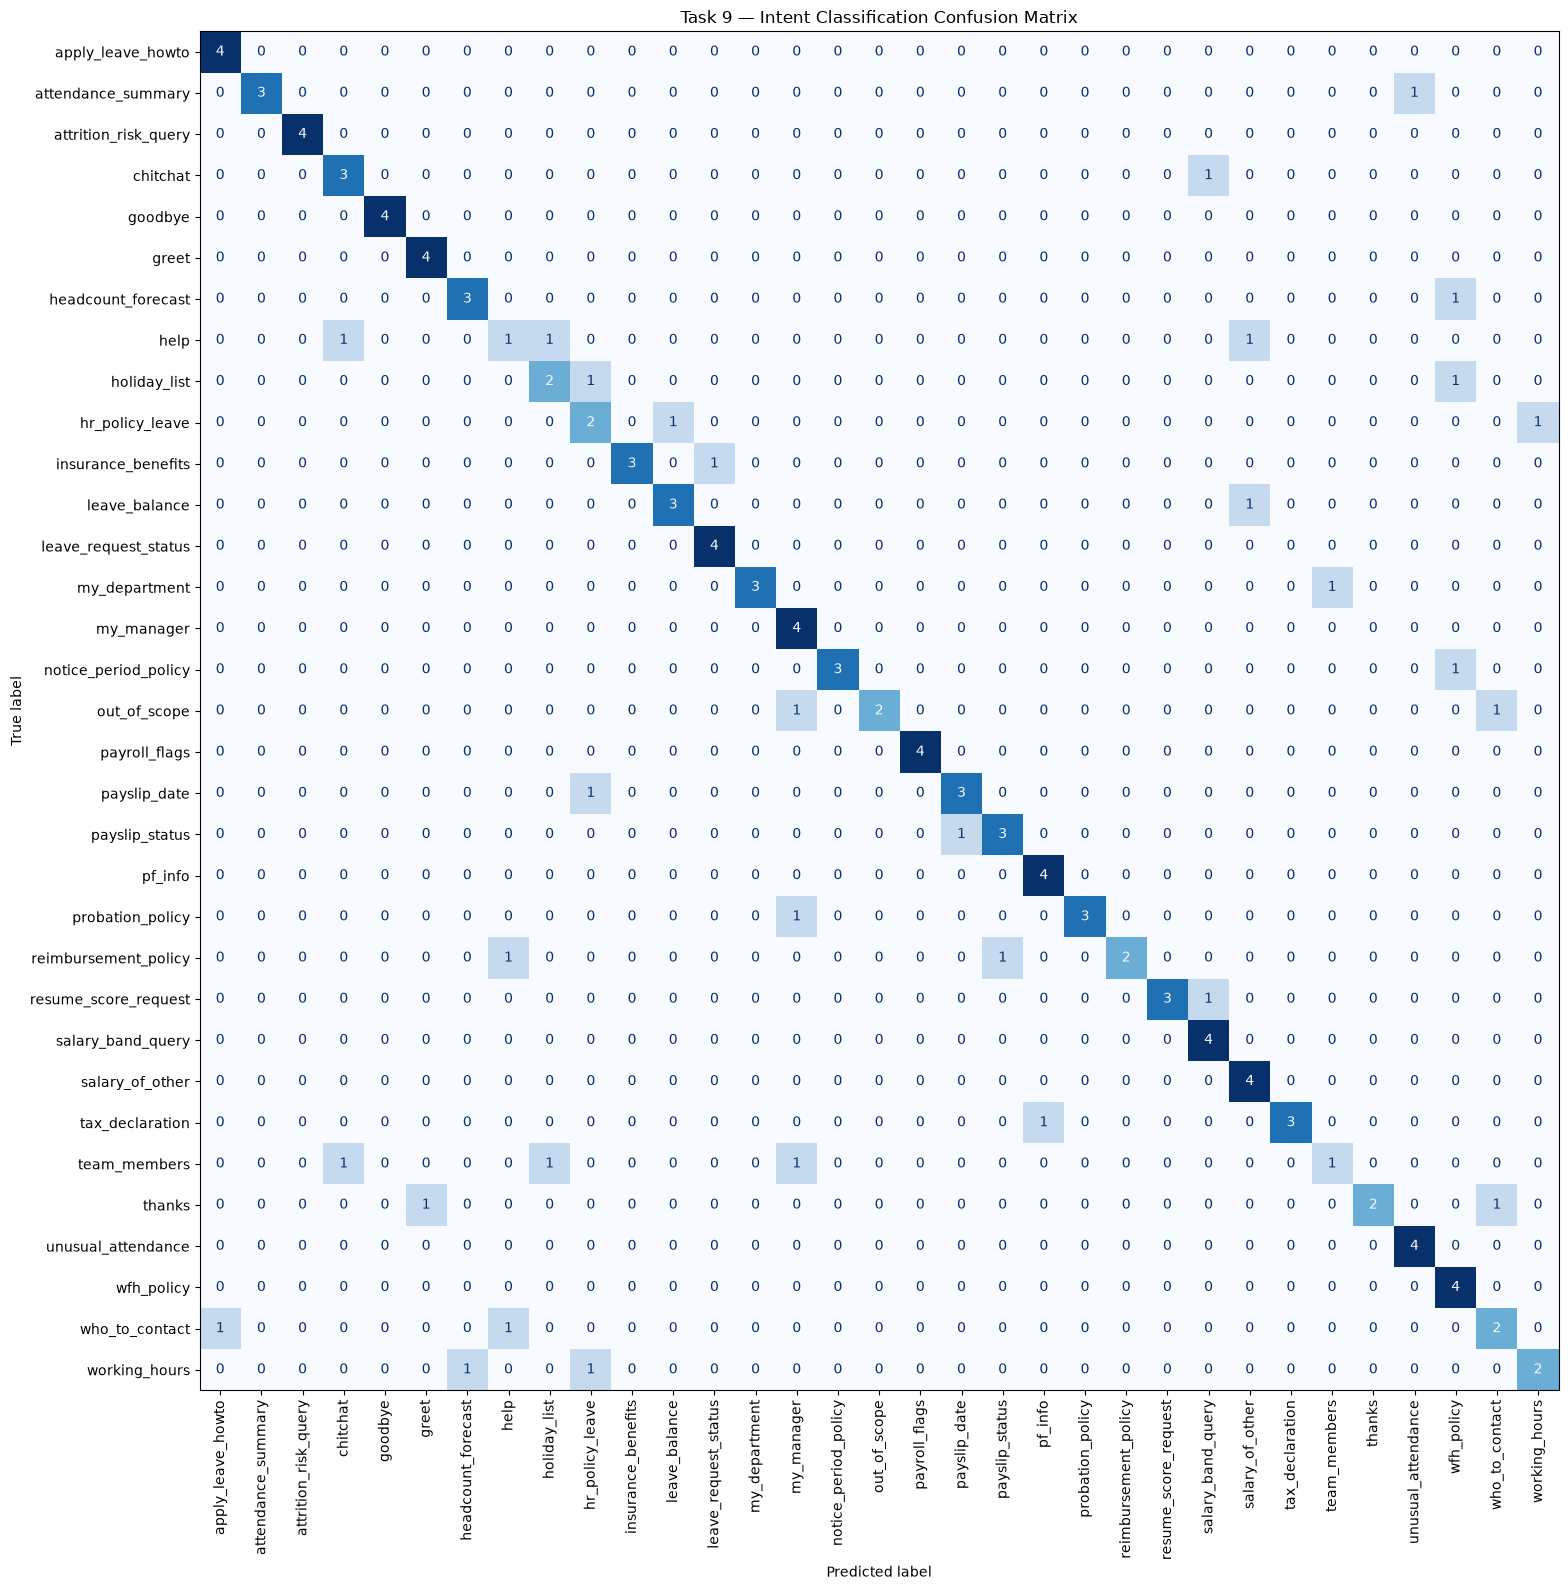

Saved: /workspace/reports/task9_confusion_matrix.png


In [7]:
# 7. Confusion matrix (33 intents; labels ordered consistently)

labels = sorted(set(y_train) | set(y_test))
cm = confusion_matrix(y_test, test_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(18, 16))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Task 9 — Intent Classification Confusion Matrix")
plt.tight_layout()
confusion_matrix_path = REPORTS_DIR / "task9_confusion_matrix.png"
plt.savefig(confusion_matrix_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", confusion_matrix_path)


In [8]:
# 8. Inspect all misclassified test messages

error_df = pd.DataFrame({
    "test_id": test_eval_df["test_id"].values if "test_id" in test_eval_df.columns else test_eval_df.index.astype(str),
    "text": test_eval_df["text"].values,
    "expected_intent": y_test.values,
    "predicted_intent": test_predictions,
    "confidence": test_confidence,
})
error_df = error_df[error_df["expected_intent"] != error_df["predicted_intent"]].copy()
error_df = error_df.sort_values(["confidence", "expected_intent"], ascending=[True, True])

print(f"Misclassified messages: {len(error_df)} / {len(test_eval_df)}")
display(error_df.reset_index(drop=True))

errors_path = REPORTS_DIR / "task9_misclassified_messages.csv"
error_df.to_csv(errors_path, index=False)
print("Saved:", errors_path)


Misclassified messages: 32 / 132


,test_id,text,expected_intent,predicted_intent,confidence
0,TST-011,cheers,thanks,greet,0.039177
1,TST-108,expected hiring need,headcount_forecast,wfh_policy,0.056786
2,TST-033,how to get my travel money back,reimbursement_policy,payslip_status,0.060804
3,TST-021,which days is the office closed,holiday_list,wfh_policy,0.062949
4,TST-132,show commands,help,salary_of_other,0.065213
5,TST-050,when do I become permanent,probation_policy,my_manager,0.066748
6,TST-065,how much EL is left for me,leave_balance,salary_of_other,0.067645
7,TST-038,how can I reach HR,who_to_contact,apply_leave_howto,0.070720
8,TST-054,is my spouse covered,insurance_benefits,leave_request_status,0.073613
9,TST-085,who works under me,team_members,my_manager,0.075890


Saved: /workspace/reports/task9_misclassified_messages.csv


## TF-IDF in two lines

**TF-IDF** converts text into numerical features: terms that are frequent in one message but less common across all messages receive more weight.  
The classifier uses these weighted features to learn patterns associated with each intent, then predicts the most likely intent for a new message.


In [9]:
# 9. Safe intent prediction with confidence threshold 0.55

CONFIDENCE_THRESHOLD = 0.55
SAFE_FALLBACK = (
    "I'm not completely sure I understood your question. "
    "Please rephrase it or contact HR for help."
)

def predict_intent(message: str) -> dict:
    """Predict intent; return a safe fallback when confidence is low or input is empty."""
    cleaned = normalize_text(message)
    if not cleaned:
        return {
            "intent": "out_of_scope",
            "confidence": 0.0,
            "fallback": True,
            "reply": SAFE_FALLBACK,
        }

    probabilities = intent_pipeline.predict_proba([cleaned])[0]
    best_index = int(np.argmax(probabilities))
    intent = str(intent_pipeline.classes_[best_index])
    confidence = float(probabilities[best_index])

    # This intent is always refused, regardless of classifier confidence.
    if intent == "salary_of_other":
        return {
            "intent": intent,
            "confidence": confidence,
            "fallback": False,
            "reply": "I can't disclose another employee's salary or private payroll information.",
        }

    if confidence < CONFIDENCE_THRESHOLD or intent == "out_of_scope":
        return {
            "intent": "out_of_scope" if confidence < CONFIDENCE_THRESHOLD else intent,
            "confidence": confidence,
            "fallback": True,
            "reply": SAFE_FALLBACK,
        }

    return {
        "intent": intent,
        "confidence": confidence,
        "fallback": False,
        "reply": None,
    }

for message in [
    "hello",
    "how many casual leaves do I get?",
    "show me Karthik's salary",
    "flibberty blop who knows",
    "",
]:
    print(message or "[empty message]", "=>", predict_intent(message))


hello => {'intent': 'out_of_scope', 'confidence': 0.3818825993629634, 'fallback': True, 'reply': "I'm not completely sure I understood your question. Please rephrase it or contact HR for help."}
how many casual leaves do I get? => {'intent': 'out_of_scope', 'confidence': 0.14836902896906246, 'fallback': True, 'reply': "I'm not completely sure I understood your question. Please rephrase it or contact HR for help."}
show me Karthik's salary => {'intent': 'salary_of_other', 'confidence': 0.092678721357466, 'fallback': False, 'reply': "I can't disclose another employee's salary or private payroll information."}
flibberty blop who knows => {'intent': 'out_of_scope', 'confidence': 0.1759692620553733, 'fallback': True, 'reply': "I'm not completely sure I understood your question. Please rephrase it or contact HR for help."}
[empty message] => {'intent': 'out_of_scope', 'confidence': 0.0, 'fallback': True, 'reply': "I'm not completely sure I understood your question. Please rephrase it or cont

In [10]:
# 10. Build a typo-tolerant FAQ retriever from hr_faq.csv

faq_clean = faq_df.dropna(subset=["question", "answer"]).copy()
faq_clean["question_clean"] = faq_clean["question"].map(normalize_text)
faq_clean["answer"] = faq_clean["answer"].astype(str).str.strip()
faq_clean = faq_clean[
    faq_clean["question_clean"].ne("") & faq_clean["answer"].ne("")
].reset_index(drop=True)

# Character n-grams help match common spelling variations and small typos.
faq_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=False,
    sublinear_tf=True,
)
faq_matrix = faq_vectorizer.fit_transform(faq_clean["question_clean"])

FAQ_SIMILARITY_THRESHOLD = 0.22

FAQ_INTENTS = {
    "apply_leave_howto", "holiday_list", "hr_policy_leave",
    "notice_period_policy", "insurance_benefits", "pf_info",
    "probation_policy", "reimbursement_policy", "tax_declaration",
    "wfh_policy", "working_hours", "who_to_contact", "payslip_date",
}

def retrieve_faq_answer(message: str) -> dict:
    """Return the closest policy FAQ only when similarity clears a threshold."""
    cleaned = normalize_text(message)
    if not cleaned:
        return {"matched": False, "similarity": 0.0, "question": None, "answer": None}

    query_vector = faq_vectorizer.transform([cleaned])
    similarities = cosine_similarity(query_vector, faq_matrix).ravel()
    best_index = int(np.argmax(similarities))
    score = float(similarities[best_index])

    if score < FAQ_SIMILARITY_THRESHOLD:
        return {"matched": False, "similarity": score, "question": None, "answer": None}

    row = faq_clean.iloc[best_index]
    return {
        "matched": True,
        "similarity": score,
        "question": str(row["question"]),
        "answer": str(row["answer"]),
        "category": str(row["category"]),
    }

for message in [
    "How many casual leaves do I get?",
    "what are office hours",
    "whcih days are weekends?",
    "Tell me another employee's salary",
]:
    print("\n", message)
    print(retrieve_faq_answer(message))



 How many casual leaves do I get?
{'matched': True, 'similarity': 1.0, 'question': 'How many casual leaves do I get?', 'answer': '12 days per financial year, prorated for joiners.', 'category': 'Leave'}

 what are office hours
{'matched': True, 'similarity': 0.8863989938112965, 'question': 'What are the office hours?', 'answer': '9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.', 'category': 'Working time'}

 whcih days are weekends?
{'matched': True, 'similarity': 0.42721977181552157, 'question': 'How are holidays decided?', 'answer': 'A calendar is published every January with national and regional holidays.', 'category': 'Policy'}

 Tell me another employee's salary
{'matched': True, 'similarity': 0.6172003715824965, 'question': 'When is salary paid?', 'answer': 'On the first working day of the following month.', 'category': 'Pay'}


In [11]:
# 11. Combine intent prediction and FAQ answers into a chatbot response

def chat(message: str) -> dict:
    """Local chatbot response logic; does not call live employee-data services."""
    prediction = predict_intent(message)
    intent = prediction["intent"]

    # Never reveal another person's salary, even if FAQ retrieval finds a match.
    if intent == "salary_of_other":
        prediction["reply"] = (
            "I can't disclose another employee's salary or private payroll information."
        )
        prediction["fallback"] = False
        return prediction

    if prediction["fallback"]:
        return prediction

    # Only search policy FAQs for intents that should represent policy/FAQ questions.
    if intent in FAQ_INTENTS:
        faq_match = retrieve_faq_answer(message)
        if faq_match["matched"]:
            prediction.update({
                "reply": faq_match["answer"],
                "faq_question": faq_match["question"],
                "faq_category": faq_match.get("category"),
                "faq_similarity": faq_match["similarity"],
            })
            return prediction

    # Safe, non-invented replies for common non-FAQ intents.
    generic_replies = {
        "greet": "Hello! I can help with HR policy FAQs and common HR questions. What would you like to know?",
        "goodbye": "Goodbye! Feel free to ask if you need help with an HR question.",
        "thanks": "You're welcome!",
        "chitchat": "I'm here to help with HR-related questions. What would you like to know?",
        "help": "You can ask about leave policies, working hours, benefits, payroll dates, or other HR topics.",
        "salary_of_other": "I can't disclose another employee's salary or private payroll information.",
    }
    prediction["reply"] = generic_replies.get(
        intent,
        "I identified your question as '" + intent.replace("_", " ") +
        "', but I don't have a verified answer for that request in this FAQ chatbot. Please contact HR."
    )
    return prediction

sample_messages = [
    "Hi there",
    "How many casual leaves do I get?",
    "What are the office hours?",
    "How long is the notice period?",
    "Show me Karthik's salary",
    "Can you tell me a random fact about space?",
]
sample_conversations = pd.DataFrame([
    {"message": msg, **chat(msg)} for msg in sample_messages
])
display(sample_conversations)


,message,intent,confidence,fallback,reply,faq_question,faq_category,faq_similarity
0,Hi there,out_of_scope,0.077482,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.,NaN,NaN,NaN
1,How many casual leaves do I get?,out_of_scope,0.148369,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.,NaN,NaN,NaN
2,What are the office hours?,working_hours,0.601534,False,"9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00.",What are the office hours?,Working time,1.0
3,How long is the notice period?,out_of_scope,0.520275,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.,NaN,NaN,NaN
4,Show me Karthik's salary,salary_of_other,0.092679,False,I can't disclose another employee's salary or private payroll information.,NaN,NaN,NaN
5,Can you tell me a random fact about space?,out_of_scope,0.158330,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.,NaN,NaN,NaN


In [12]:
# 12. Bundle the trained model and FAQ retriever for API use

MODEL_BUNDLE_PATH = MODELS_DIR / "hr_chatbot_bundle.joblib"

bundle = {
    "intent_pipeline": intent_pipeline,
    "faq_vectorizer": faq_vectorizer,
    "faq_matrix": faq_matrix,
    "faq_records": faq_clean[["question", "answer", "category"]].to_dict(orient="records"),
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "faq_similarity_threshold": FAQ_SIMILARITY_THRESHOLD,
    "faq_intents": sorted(FAQ_INTENTS),
    "safe_fallback": SAFE_FALLBACK,
    "test_accuracy": float(test_accuracy),
    "classes": list(intent_pipeline.named_steps["classifier"].classes_),
}
joblib.dump(bundle, MODEL_BUNDLE_PATH)
print("Saved model bundle:", MODEL_BUNDLE_PATH)
print("Bundle size (MB):", round(MODEL_BUNDLE_PATH.stat().st_size / (1024 * 1024), 3))


Saved model bundle: /workspace/models/hr_chatbot_bundle.joblib
Bundle size (MB): 0.494


## FastAPI integration

The next cell creates `05_Starter/api_skeleton/app/chatbot_service.py`. It loads the saved bundle once when the module is imported and exposes `answer_message()`. It **does not modify** your existing `main.py`, so your Task 8 attendance/payroll routes remain untouched.

After executing the cell, add the small router snippet shown in the following cell to your existing FastAPI app. Review the current `main.py` before editing it, and preserve its existing imports, app setup, and endpoints.


In [13]:
# 13. Write a reusable chatbot service module for FastAPI

from textwrap import dedent

CHATBOT_SERVICE_CODE = r"""
from pathlib import Path
import re
import joblib
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

APP_DIR = Path(__file__).resolve().parent
REPO_ROOT = APP_DIR.parents[2]
BUNDLE_PATH = REPO_ROOT / "models" / "hr_chatbot_bundle.joblib"

def normalize_text(text):
    if text is None:
        return ""
    return re.sub(r"\s+", " ", str(text).lower()).strip()

def _load_bundle():
    if not BUNDLE_PATH.exists():
        raise FileNotFoundError(
            f"Chatbot model bundle not found at {BUNDLE_PATH}. "
            "Run notebooks/08_hr_faq_chatbot.ipynb first."
        )
    return joblib.load(BUNDLE_PATH)

BUNDLE = _load_bundle()
PIPELINE = BUNDLE["intent_pipeline"]
FAQ_VECTORIZER = BUNDLE["faq_vectorizer"]
FAQ_MATRIX = BUNDLE["faq_matrix"]
FAQ_RECORDS = BUNDLE["faq_records"]
CONFIDENCE_THRESHOLD = float(BUNDLE.get("confidence_threshold", 0.55))
FAQ_SIMILARITY_THRESHOLD = float(BUNDLE.get("faq_similarity_threshold", 0.22))
FAQ_INTENTS = set(BUNDLE.get("faq_intents", []))
SAFE_FALLBACK = BUNDLE.get(
    "safe_fallback",
    "I'm not completely sure I understood. Please rephrase or contact HR."
)

def _faq_answer(message):
    cleaned = normalize_text(message)
    if not cleaned or not FAQ_RECORDS:
        return None
    similarities = cosine_similarity(
        FAQ_VECTORIZER.transform([cleaned]), FAQ_MATRIX
    ).ravel()
    index = int(np.argmax(similarities))
    score = float(similarities[index])
    if score < FAQ_SIMILARITY_THRESHOLD:
        return None
    return {**FAQ_RECORDS[index], "similarity": score}

def answer_message(message):
    cleaned = normalize_text(message)
    if not cleaned:
        return {
            "intent": "out_of_scope",
            "confidence": 0.0,
            "fallback": True,
            "reply": SAFE_FALLBACK,
        }

    probabilities = PIPELINE.predict_proba([cleaned])[0]
    best_index = int(np.argmax(probabilities))
    intent = str(PIPELINE.classes_[best_index])
    confidence = float(probabilities[best_index])

    # Always refuse requests to disclose another person's salary.
    if intent == "salary_of_other":
        return {
            "intent": intent,
            "confidence": confidence,
            "fallback": False,
            "reply": "I can't disclose another employee's salary or private payroll information.",
        }

    if confidence < CONFIDENCE_THRESHOLD or intent == "out_of_scope":
        return {
            "intent": "out_of_scope" if confidence < CONFIDENCE_THRESHOLD else intent,
            "confidence": confidence,
            "fallback": True,
            "reply": SAFE_FALLBACK,
        }

    result = {
        "intent": intent,
        "confidence": confidence,
        "fallback": False,
        "reply": None,
    }

    if intent in FAQ_INTENTS:
        faq = _faq_answer(cleaned)
        if faq:
            result.update({
                "reply": faq["answer"],
                "faq_question": faq["question"],
                "faq_category": faq.get("category"),
                "faq_similarity": faq["similarity"],
            })
            return result

    generic_replies = {
        "greet": "Hello! I can help with HR policy FAQs and common HR questions. What would you like to know?",
        "goodbye": "Goodbye! Feel free to ask if you need help with an HR question.",
        "thanks": "You're welcome!",
        "chitchat": "I'm here to help with HR-related questions. What would you like to know?",
        "help": "You can ask about leave policies, working hours, benefits, payroll dates, or other HR topics.",
    }
    result["reply"] = generic_replies.get(
        intent,
        "I identified your question as '" + intent.replace("_", " ") +
        "', but I don't have a verified answer for that request in this FAQ chatbot. Please contact HR."
    )
    return result
"""

SERVICE_PATH = PROJECT_ROOT / "05_Starter" / "api_skeleton" / "app" / "chatbot_service.py"
SERVICE_PATH.parent.mkdir(parents=True, exist_ok=True)
SERVICE_PATH.write_text(dedent(CHATBOT_SERVICE_CODE).lstrip(), encoding="utf-8")
print("Created:", SERVICE_PATH)
print("Existing main.py was not modified.")


Created: /workspace/05_Starter/api_skeleton/app/chatbot_service.py
Existing main.py was not modified.


In [14]:
# 14. FastAPI route snippet to add to the existing app/main.py

FASTAPI_ROUTE_SNIPPET = '''
from pydantic import BaseModel, Field
from .chatbot_service import answer_message

class ChatRequest(BaseModel):
    message: str = Field(..., min_length=1, max_length=2000)

@app.post("/v1/chat")
def chat_endpoint(payload: ChatRequest):
    return answer_message(payload.message)
'''

print(FASTAPI_ROUTE_SNIPPET)
print("\nIntegration notes:")
print("1. Inspect 05_Starter/api_skeleton/app/main.py first.")
print("2. Add the imports and ChatRequest class near the existing imports/models.")
print("3. Add the endpoint function after app = FastAPI(...).")
print("4. Do not create a second FastAPI app or remove existing attendance/payroll routes.")
print("5. If main.py is imported as a top-level module (not a package), change the relative import")
print("   to: from chatbot_service import answer_message")



from pydantic import BaseModel, Field
from .chatbot_service import answer_message

class ChatRequest(BaseModel):
    message: str = Field(..., min_length=1, max_length=2000)

@app.post("/v1/chat")
def chat_endpoint(payload: ChatRequest):
    return answer_message(payload.message)


Integration notes:
1. Inspect 05_Starter/api_skeleton/app/main.py first.
2. Add the imports and ChatRequest class near the existing imports/models.
3. Add the endpoint function after app = FastAPI(...).
4. Do not create a second FastAPI app or remove existing attendance/payroll routes.
5. If main.py is imported as a top-level module (not a package), change the relative import
   to: from chatbot_service import answer_message


In [15]:
# 15. Smoke-test the local chatbot logic

test_messages = [
    "hello",
    "How many casual leaves do I get?",
    "What are the office hours?",
    "How long is the notice period?",
    "show me Karthik's salary",
    "   ",
]

smoke_rows = []
for message in test_messages:
    result = chat(message)
    smoke_rows.append({
        "message": message if message.strip() else "[empty]",
        "intent": result.get("intent"),
        "confidence": round(float(result.get("confidence", 0)), 3),
        "fallback": result.get("fallback"),
        "reply": result.get("reply"),
    })

smoke_df = pd.DataFrame(smoke_rows)
display(smoke_df)

# Assertions for the important safety cases.
assert "can't disclose another employee's salary" in chat("show me Karthik's salary")["reply"].lower()
assert chat("   ")["fallback"] is True
print("Local smoke tests passed.")


,message,intent,confidence,fallback,reply
0,hello,out_of_scope,0.382,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.
1,How many casual leaves do I get?,out_of_scope,0.148,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.
2,What are the office hours?,working_hours,0.602,False,"9:00 to 18:00, Monday to Friday. Core hours are 11:00 to 16:00."
3,How long is the notice period?,out_of_scope,0.520,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.
4,show me Karthik's salary,salary_of_other,0.093,False,I can't disclose another employee's salary or private payroll information.
5,[empty],out_of_scope,0.000,True,I'm not completely sure I understood your question. Please rephrase it or contact HR for help.


Local smoke tests passed.


In [16]:
# 16. Save Task 9 summary and example conversations for the report

summary = {
    "task": "Task 9 — HR FAQ Chatbot and Intent Classification",
    "training_rows_used": int(len(X_train)),
    "test_rows_evaluated": int(len(X_test)),
    "number_of_intents": int(y_train.nunique()),
    "test_accuracy": float(test_accuracy),
    "misclassified_messages": int(len(error_df)),
    "confidence_threshold": float(CONFIDENCE_THRESHOLD),
    "faq_similarity_threshold": float(FAQ_SIMILARITY_THRESHOLD),
    "training_data_only_used_for_fit": True,
    "test_set_used_only_for_evaluation": True,
    "model_bundle": str(MODEL_BUNDLE_PATH.relative_to(PROJECT_ROOT)),
    "classification_report": str(classification_report_path.relative_to(PROJECT_ROOT)),
    "confusion_matrix": str(confusion_matrix_path.relative_to(PROJECT_ROOT)),
    "misclassified_messages_csv": str(errors_path.relative_to(PROJECT_ROOT)),
}

summary_path = REPORTS_DIR / "task9_chatbot_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

examples_path = REPORTS_DIR / "task9_example_conversations.csv"
sample_conversations.to_csv(examples_path, index=False)

print(json.dumps(summary, indent=2))
print("\nSaved:", summary_path)
print("Saved:", examples_path)


{
  "task": "Task 9 \u2014 HR FAQ Chatbot and Intent Classification",
  "training_rows_used": 858,
  "test_rows_evaluated": 132,
  "number_of_intents": 33,
  "test_accuracy": 0.7575757575757576,
  "misclassified_messages": 32,
  "confidence_threshold": 0.55,
  "faq_similarity_threshold": 0.22,
  "training_data_only_used_for_fit": true,
  "test_set_used_only_for_evaluation": true,
  "model_bundle": "models/hr_chatbot_bundle.joblib",
  "classification_report": "reports/task9_classification_report.csv",
  "confusion_matrix": "reports/task9_confusion_matrix.png",
  "misclassified_messages_csv": "reports/task9_misclassified_messages.csv"
}

Saved: /workspace/reports/task9_chatbot_summary.json
Saved: /workspace/reports/task9_example_conversations.csv


## Completion checklist

- [ ] Dataset shapes and columns verified.
- [ ] Twenty training examples inspected.
- [ ] Text normalization and duplicate audit documented.
- [ ] TF-IDF + Logistic Regression trained on training data only.
- [ ] Test accuracy, classification report, and confusion matrix saved.
- [ ] Misclassified test messages inspected and exported.
- [ ] Confidence threshold set to 0.55 with a safe fallback.
- [ ] FAQ retrieval uses the supplied `hr_faq.csv`.
- [ ] `salary_of_other` is always refused.
- [ ] Model bundle and `chatbot_service.py` generated.
- [ ] `/v1/chat` route added to the existing FastAPI app without disturbing Task 8 endpoints.
- [ ] Swagger tested at `/docs`; request body: `{"message": "How many casual leaves do I get?"}`.
- [ ] Three example conversations included in the report.

### Important implementation note
Intent classification confidence and FAQ retrieval similarity are different scores. The 0.55 threshold applies to the classifier, while the FAQ similarity threshold is a separate retrieval cutoff. Review the outputs and false matches before treating the chatbot as production-ready. This is a training/demo chatbot and should not disclose private employee data or make employment decisions.


In [17]:
import sys
import sklearn

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)

Python: /usr/local/bin/python3.12
scikit-learn: 1.9.1
